# 🌊 MaCVi - EURS: Comprehensive Exploratory Data Analysis & Competition Guide

Welcome to the in-depth Exploratory Data Analysis (EDA) notebook for the **MaCVi (Maritime Computer Vision) EURS (Enhanced Underwater Real-world Salient/Restoration)** benchmark challenge.

---

### 🏆 Challenge Task & Tracks Summary (from OVERVIEW.md)

The EURS challenge tackles **joint pixel-level underwater image restoration and semantic understanding** on real-world marine scenes:

1. **Input**: A degraded underwater image $(1, 3, H, W)$ exhibiting severe wavelength-dependent color absorption, backscattering haze, and low contrast.
2. **Output 1 — Restored Image**: Clean RGB scene $(1, 3, H, W)$ in $[0, 1]$ float range.
3. **Output 2 — Segmentation Mask**: Semantic pixel labeling across **5 discrete classes**:
   - **`0: Background`** (water column, open seabed sand)
   - **`1: Coral`** (reef structures, benthic substrate)
   - **`2: Fish`** (bony fishes, solitary / schooling)
   - **`3: Elasmobranch`** (sharks, rays, skates)
   - **`4: Other`** (starfish, sea turtles, seahorses, divers, other marine organisms)

| Track | Evaluation Environment | Key Constraints / Metric Weight |
| :--- | :--- | :--- |
| **Track 1: Public Dev Leaderboard** | Server-side evaluation on Dev split | Submissions: `.zip` with `restored/` & `seg_masks/` (PNGs 0–4, resized via `resize_for_submission.py`). |
| **Track 2: Embedded Hardware** | Physical **Jetson AGX Orin** (30W mode) | Submissions: Static `.onnx` graph $\le \mathbf{12\text{ GFLOPs}}$ and $\le \mathbf{1.0\text{M params}}$. Inputs $(1, 3, H, W) \in [0, 1]$, outputs `restored_image` $(1, 3, H, W)$ and `seg_logits` $(1, 5, H, W)$. |

### 📊 Official Ranking Metric Formula
$$\text{Composite} = 0.6 \times Q_{\text{seg}} + 0.3 \times \left(0.45 \times \text{PSNR}_{\text{norm}} + 0.45 \times \text{SSIM} + 0.10 \times \text{sharpness\_ratio}\right) + 0.1 \times \text{NRquality}$$
- **Segmentation Quality ($Q_{\text{seg}}$)**: $\text{F1} \times \text{mIoU} \times \text{coverage\_penalty}$ (heaviest weight: 60%).
- **Normalized PSNR ($\text{PSNR}_{\text{norm}}$)**: $\text{clip}\left(\frac{\text{PSNR} - 15}{35 - 15}, 0, 1\right)$.
- **Sharpness Ratio**: Anti-blur metric computing high-frequency Laplacian variance of restored vs. GT.
- **NRquality**: Mean of no-reference underwater quality metrics (UIQM, UCIQE, CCF).

---

### 🎯 Notebook Outline
1. **Environment Setup & 5-Class Visualization Palettes**
2. **Directory Indexing & Filename Parameter Deconstruction**
3. **Sequence Distribution & Group-KFold Leakage Prevention**
4. **Image Dimensions, Aspect Ratios & Static Resolution Analysis**
5. **Multi-Task Triplet Inspection: 5-Class Semantic Overlays**
6. **Degradation Spectrum: Turbidity & Attenuation Progression**
7. **Underwater Color Profile & Channel Attenuation (RGB / LAB / HSV)**
8. **Degradation Quality Benchmarks (PSNR, SSIM & Sharpness Ratio)**
9. **Frequency Domain Profiling (2D Fourier Transform / FFT)**
10. **5-Class Mask Pixel Frequencies, Imbalance & Spatial Heatmaps**
11. **Unified Modeling Strategy (Dual-Head Network $\le 12$ GFLOPs)**

---  
## 1. Environment Setup & 5-Class Visualization Palettes

We configure the working environment, verify data paths, and define the official 5-class color scheme:
- `0: Background` $\to$ Slate Navy `[15, 23, 42]`
- `1: Coral` $\to$ Coral Orange `[249, 115, 22]`
- `2: Fish` $\to$ Amber Gold `[234, 179, 8]`
- `3: Elasmobranch` $\to$ Cyan Blue `[6, 182, 212]`
- `4: Other` $\to$ Vivid Magenta `[236, 72, 153]`

In [1]:
import os
import re
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import seaborn as sns
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from tqdm.notebook import tqdm

# Set global plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# Dataset Root Configuration
KAGGLE_DATASET_ROOT = Path("/kaggle/input/datasets/thnhtt/macvi-eurs")
LOCAL_FALLBACK_ROOT = Path("./dataset")
DATASET_ROOT = KAGGLE_DATASET_ROOT if KAGGLE_DATASET_ROOT.exists() else LOCAL_FALLBACK_ROOT
print(f"[INFO] Active Dataset Root: {DATASET_ROOT.resolve()}")

TRAIN_DEGRADED_DIR = DATASET_ROOT / "eurs_train-001" / "train" / "degraded"
TRAIN_GT_IMG_DIR = DATASET_ROOT / "eurs_train-001" / "train" / "gt_images"
TRAIN_GT_MASK_DIR = DATASET_ROOT / "eurs_train-001" / "train" / "gt_masks"
DEV_DEGRADED_DIR = DATASET_ROOT / "eurs_dev_degraded-002" / "dev" / "degraded"

for name, p in [
    ("Train Degraded", TRAIN_DEGRADED_DIR),
    ("Train GT Images", TRAIN_GT_IMG_DIR),
    ("Train GT Masks", TRAIN_GT_MASK_DIR),
    ("Dev Degraded", DEV_DEGRADED_DIR)
]:
    print(f"- {name:18}: {'Found' if p.exists() else 'Not found'} ({p})")

# Define 5 Semantic Classes and Custom Discrete Colormap
CLASS_NAMES = ['Background', 'Coral', 'Fish', 'Elasmobranch', 'Other']
CLASS_COLORS_RGB = np.array([
    [15, 23, 42],     # 0: Background (Dark Slate)
    [249, 115, 22],   # 1: Coral (Orange)
    [234, 179, 8],    # 2: Fish (Gold / Yellow)
    [6, 182, 212],    # 3: Elasmobranch (Cyan)
    [236, 72, 153],   # 4: Other (Magenta)
], dtype=np.uint8)

# Normalize for Matplotlib ListedColormap
CLASS_CMAP = mcolors.ListedColormap(CLASS_COLORS_RGB / 255.0)
CLASS_NORM = mcolors.BoundaryNorm(boundaries=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], ncolors=5)

print("\n[INFO] 5-Class Palette Initialized:")
for idx, (cname, rgb) in enumerate(zip(CLASS_NAMES, CLASS_COLORS_RGB)):
    print(f"  Class {idx}: {cname:13} -> RGB{tuple(rgb)}")

[INFO] Active Dataset Root: /kaggle/input/datasets/thnhtt/macvi-eurs
- Train Degraded    : Found (/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_train-001/train/degraded)
- Train GT Images   : Found (/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_train-001/train/gt_images)
- Train GT Masks    : Found (/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_train-001/train/gt_masks)
- Dev Degraded      : Found (/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_dev_degraded-002/dev/degraded)

[INFO] 5-Class Palette Initialized:
  Class 0: Background    -> RGB(np.uint8(15), np.uint8(23), np.uint8(42))
  Class 1: Coral         -> RGB(np.uint8(249), np.uint8(115), np.uint8(22))
  Class 2: Fish          -> RGB(np.uint8(234), np.uint8(179), np.uint8(8))
  Class 3: Elasmobranch  -> RGB(np.uint8(6), np.uint8(182), np.uint8(212))
  Class 4: Other         -> RGB(np.uint8(236), np.uint8(72), np.uint8(153))


---  
## 2. Directory Indexing & Filename Metadata Parsing

### Why this parsing matters:
Each degraded file follows a structured naming syntax:
$$\mathbf{\{sequence\_name\}\_\{param1\}\_\{param2\}.png}$$
- `sequence_name`: The underlying biological scene (e.g. `fish1`, `sharkFish`, `turtles1`).
- `param1` & `param2`: Synthetic degradation levels simulating water depth, turbidity, and backscatter coefficient.

We index the dataset into a structured DataFrame and verify triplet pairing between degraded images, clean GT targets, and 5-class segmentation masks.

In [2]:
def parse_filename(filepath: Path):
    """
    Deconstructs filename into sequence name and degradation parameter tokens.
    Example: sharkFish_2_45.png -> sequence='sharkFish', param1=2, param2=45
    """
    stem = filepath.stem
    parts = stem.split("_")
    if len(parts) >= 3:
        seq = "_".join(parts[:-2])
        param1 = parts[-2]
        param2 = parts[-1]
    elif len(parts) == 2:
        seq = parts[0]
        param1 = parts[1]
        param2 = None
    else:
        seq = stem
        param1, param2 = None, None
    
    return {
        "filename": filepath.name,
        "sequence": seq,
        "param1": int(param1) if param1 and param1.isdigit() else param1,
        "param2": int(param2) if param2 and param2.isdigit() else param2,
        "path": str(filepath)
    }

# Index Train Split
train_records = []
if TRAIN_DEGRADED_DIR.exists():
    for f in TRAIN_DEGRADED_DIR.rglob("*.png"):
        rec = parse_filename(f)
        rec["split"] = "train"
        rec["folder_sequence"] = f.parent.name
        
        # Check matching GT clean image
        gt_img_exact = TRAIN_GT_IMG_DIR / f.name
        gt_img_seq = TRAIN_GT_IMG_DIR / f"{rec['sequence']}.png"
        gt_img_folder_seq = TRAIN_GT_IMG_DIR / f"{f.parent.name}.png"
        
        if gt_img_exact.exists():
            rec["gt_image_path"] = str(gt_img_exact)
        elif gt_img_seq.exists():
            rec["gt_image_path"] = str(gt_img_seq)
        elif gt_img_folder_seq.exists():
            rec["gt_image_path"] = str(gt_img_folder_seq)
        else:
            nested_gt = list(TRAIN_GT_IMG_DIR.glob(f"**/{rec['sequence']}*.png"))
            rec["gt_image_path"] = str(nested_gt[0]) if len(nested_gt) > 0 else None

        # Check matching GT 5-class mask
        gt_mask_exact = TRAIN_GT_MASK_DIR / f.name
        gt_mask_seq = TRAIN_GT_MASK_DIR / f"{rec['sequence']}.png"
        gt_mask_folder_seq = TRAIN_GT_MASK_DIR / f"{f.parent.name}.png"
        
        if gt_mask_exact.exists():
            rec["gt_mask_path"] = str(gt_mask_exact)
        elif gt_mask_seq.exists():
            rec["gt_mask_path"] = str(gt_mask_seq)
        elif gt_mask_folder_seq.exists():
            rec["gt_mask_path"] = str(gt_mask_folder_seq)
        else:
            nested_mask = list(TRAIN_GT_MASK_DIR.glob(f"**/{rec['sequence']}*.png"))
            rec["gt_mask_path"] = str(nested_mask[0]) if len(nested_mask) > 0 else None
            
        train_records.append(rec)

df_train = pd.DataFrame(train_records)

# Index Dev Split (Degraded inputs only - scored server-side)
dev_records = []
if DEV_DEGRADED_DIR.exists():
    for f in DEV_DEGRADED_DIR.rglob("*.png"):
        rec = parse_filename(f)
        rec["split"] = "dev"
        rec["folder_sequence"] = f.parent.name
        rec["gt_image_path"] = None
        rec["gt_mask_path"] = None
        dev_records.append(rec)

df_dev = pd.DataFrame(dev_records)
df_all = pd.concat([df_train, df_dev], ignore_index=True) if len(df_dev) > 0 else df_train

print("=== Metadata Indexing Summary ===")
print(f"• Train Degraded Images : {len(df_train)} (with {df_train['gt_image_path'].notna().sum()} paired GT images & {df_train['gt_mask_path'].notna().sum()} paired GT masks)")
print(f"• Dev Degraded Images   : {len(df_dev)}")
print(f"• Combined Dataset Rows : {len(df_all)}")
df_all.head(6)

=== Metadata Indexing Summary ===
• Train Degraded Images : 4000 (with 4000 paired GT images & 4000 paired GT masks)
• Dev Degraded Images   : 1200
• Combined Dataset Rows : 5200


,filename,sequence,param1,param2,path,split,folder_sequence,gt_image_path,gt_mask_path
0,sharkFish_2_45.png,sharkFish,2,45,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,train,sharkFish,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...
1,sharkFish_3_75.png,sharkFish,3,75,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,train,sharkFish,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...
2,sharkFish_3_85.png,sharkFish,3,85,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,train,sharkFish,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...
3,sharkFish_7_85.png,sharkFish,7,85,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,train,sharkFish,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...
4,sharkFish_7_65.png,sharkFish,7,65,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,train,sharkFish,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...
5,sharkFish_8_20.png,sharkFish,8,20,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,train,sharkFish,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...,/kaggle/input/datasets/thnhtt/macvi-eurs/eurs_...


---  
## 3. Sequence Distribution & Group-KFold Leakage Warning

### ⚠️ Critical Note on Data Leakage & Validation Strategy
- **What the Sequence Summary Table Shows**:
  Every sequence folder (e.g. `sharkFish`, `fish1`, `turtles1`) contains $\approx 200$ degraded frames derived from the **same single clean image/mask** under various simulated water parameters.
- **The Validation Pitfall**:
  If you split training data using random K-Fold (`train_test_split`), frames from the same underlying scene will appear in both training and validation splits. The model will memorize specific textures and report artificially inflated PSNR/SSIM/mIoU scores that fail on the Dev/Test leaderboard.
- **The Solution**: **Group-K-Fold Cross-Validation** grouped strictly on `folder_sequence`.

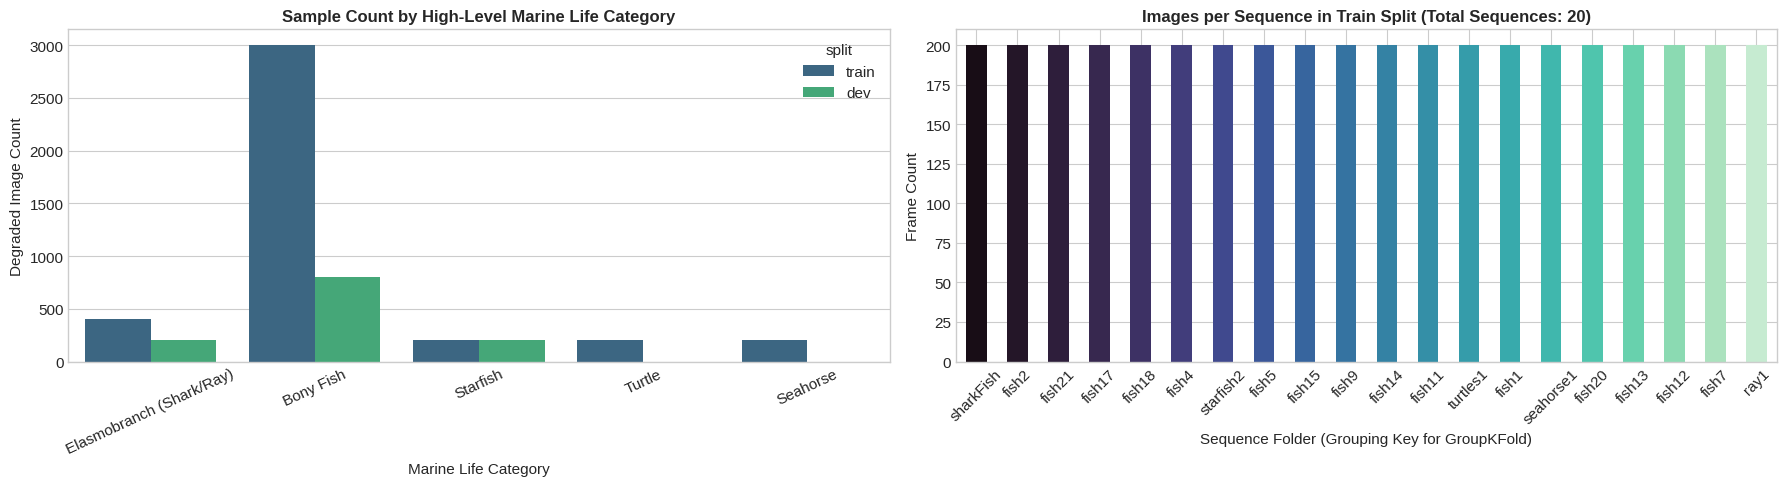


=== Sequence Summary Table across Train & Dev Splits ===


split                                     dev  train
category                 folder_sequence            
Bony Fish                fish1              0    200
                         fish10           200      0
                         fish11             0    200
                         fish12             0    200
                         fish13             0    200
                         fish14             0    200
                         fish15             0    200
                         fish17             0    200
                         fish18             0    200
                         fish19           200      0
                         fish2              0    200
                         fish20             0    200
                         fish21             0    200
                         fish3            200      0
                         fish4              0    200
                         fish5              0    200
                         fish6            200      0
                         fish7              0    200
                         fish9              0    200
Elasmobranch (Shark/Ray) ray1               0    200
                         sharRayFish      200      0
                         sharkFish          0    200
Seahorse                 seahorse1          0    200
Starfish                 starfish1        200      0
                         starfish2          0    200
Turtle                   turtles1           0    200

In [3]:
# Map sequence to semantic categories
def extract_category(seq_name):
    seq_lower = str(seq_name).lower()
    if "shark" in seq_lower or "ray" in seq_lower:
        return "Elasmobranch (Shark/Ray)"
    elif "fish" in seq_lower and "star" not in seq_lower:
        return "Bony Fish"
    elif "starfish" in seq_lower or "star" in seq_lower:
        return "Starfish"
    elif "seahorse" in seq_lower:
        return "Seahorse"
    elif "turtle" in seq_lower:
        return "Turtle"
    else:
        return "Other / Mixed"

if not df_all.empty:
    df_all["category"] = df_all["sequence"].apply(extract_category)
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    
    # 1. Samples per Split & Semantic Group
    sns.countplot(data=df_all, x="category", hue="split", ax=axes[0], palette="viridis")
    axes[0].set_title("Sample Count by High-Level Marine Life Category", fontweight="bold", fontsize=12)
    axes[0].set_xlabel("Marine Life Category")
    axes[0].set_ylabel("Degraded Image Count")
    axes[0].tick_params(axis='x', rotation=25)
    
    # 2. Sequence Folder Breakdown in Train Split
    seq_counts = df_train["folder_sequence"].value_counts()
    seq_counts.plot(kind="bar", ax=axes[1], color=sns.color_palette("mako", len(seq_counts)))
    axes[1].set_title(f"Images per Sequence in Train Split (Total Sequences: {len(seq_counts)})", fontweight="bold", fontsize=12)
    axes[1].set_xlabel("Sequence Folder (Grouping Key for GroupKFold)")
    axes[1].set_ylabel("Frame Count")
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
    
    print("\n=== Sequence Summary Table across Train & Dev Splits ===")
    summary_table = df_all.groupby(["split", "category", "folder_sequence"]).size().unstack(level="split", fill_value=0)
    display(summary_table)

---  
## 4. Image Dimensions, Aspect Ratios & Static Resolution Analysis

### Challenge Constraints on Image Resolution:
1. **Track 1 (Public Dev-Set)**: Submissions are scored at an aspect-preserved resolution with longest side capped at **$1024\text{ px}$**. Images $> 2048\text{ px}$ are rejected immediately. The starter kit script `resize_for_submission.py` must be used as the mandatory final step.
2. **Track 2 (Embedded Jetson AGX Orin)**: Requires a **static ONNX input tensor** (no dynamic axes). The reference baseline runs at **$384 \times 768$** to clear the $\le 12\text{ GFLOPs}$ cap.

We inspect the raw resolution distribution to inform our training patch size and static inference shape.

Inspecting Resolutions:   0%|          | 0/200 [00:00<?, ?it/s]

/tmp/ipykernel_16/2517288929.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_props, x="split", y="mean_val", ax=axes[2], palette="Blues")


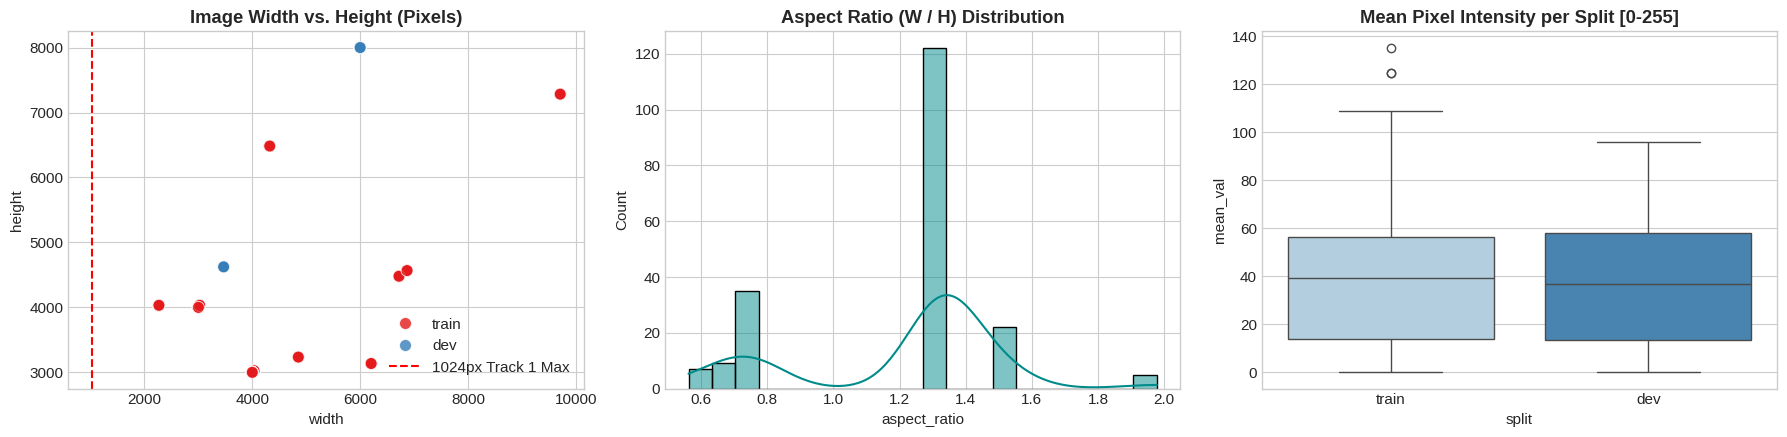

,width,height,aspect_ratio,mean_val
count,200.000000,200.000000,200.000000,200.000000
mean,4281.900000,3720.500000,1.208635,39.701850
std,1228.726223,1260.903142,0.314296,29.441063
min,2268.000000,3000.000000,0.562000,0.000000
25%,4000.000000,3000.000000,0.750000,13.675000
50%,4000.000000,3024.000000,1.333000,38.745000
75%,4032.000000,4032.000000,1.333000,57.747500
max,9710.000000,8000.000000,1.978000,135.350000


In [4]:
def inspect_image_properties(df_sample, max_samples=150):
    records = []
    samples = df_sample.sample(min(len(df_sample), max_samples), random_state=42) if len(df_sample) > 0 else df_sample
    
    for _, row in tqdm(samples.iterrows(), total=len(samples), desc="Inspecting Resolutions"):
        img_p = Path(row["path"])
        if not img_p.exists():
            continue
        
        try:
            with Image.open(img_p) as img:
                w, h = img.size
                mode = img.mode
            
            img_arr = cv2.imread(str(img_p))
            records.append({
                "split": row["split"],
                "sequence": row["sequence"],
                "width": w,
                "height": h,
                "aspect_ratio": round(w / h, 3),
                "channels": img_arr.shape[2] if img_arr is not None else 0,
                "min_val": int(img_arr.min()) if img_arr is not None else None,
                "max_val": int(img_arr.max()) if img_arr is not None else None,
                "mean_val": round(float(img_arr.mean()), 2) if img_arr is not None else None,
            })
        except Exception as e:
            print(f"Error reading {img_p}: {e}")
            
    return pd.DataFrame(records)

df_props = inspect_image_properties(df_all, max_samples=200)
if not df_props.empty:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    
    # Resolutions Scatter
    sns.scatterplot(data=df_props, x="width", y="height", hue="split", s=75, alpha=0.8, ax=axes[0], palette="Set1")
    axes[0].set_title("Image Width vs. Height (Pixels)", fontweight="bold")
    axes[0].axvline(1024, color='red', linestyle='--', label='1024px Track 1 Max')
    axes[0].legend()
    
    # Aspect Ratios
    sns.histplot(data=df_props, x="aspect_ratio", bins=20, kde=True, ax=axes[1], color="darkcyan")
    axes[1].set_title("Aspect Ratio (W / H) Distribution", fontweight="bold")
    
    # Intensity per Split
    sns.boxplot(data=df_props, x="split", y="mean_val", ax=axes[2], palette="Blues")
    axes[2].set_title("Mean Pixel Intensity per Split [0-255]", fontweight="bold")
    
    plt.tight_layout()
    plt.show()
    
    display(df_props[["width", "height", "aspect_ratio", "mean_val"]].describe())

---  
## 5. Multi-Task Triplet Inspection: 5-Class Semantic Overlays

### What this visualization demonstrates:
For each sample, we render a 4-column multi-task panel matching the challenge outputs:
1. **Degraded Image (Model Input)**: Color-cast, blurred underwater input image.
2. **GT Clean Image (Restoration Target)**: Sharp, color-accurate underwater target frame.
3. **GT 5-Class Mask (Segmentation Target)**: Color-coded semantic mask with exact class legend (`0: Background`, `1: Coral`, `2: Fish`, `3: Elasmobranch`, `4: Other`).
4. **5-Class Alpha-Blended Overlay**: Overlay of semantic mask onto the clean GT image to evaluate boundary sharpness and multi-class annotations.

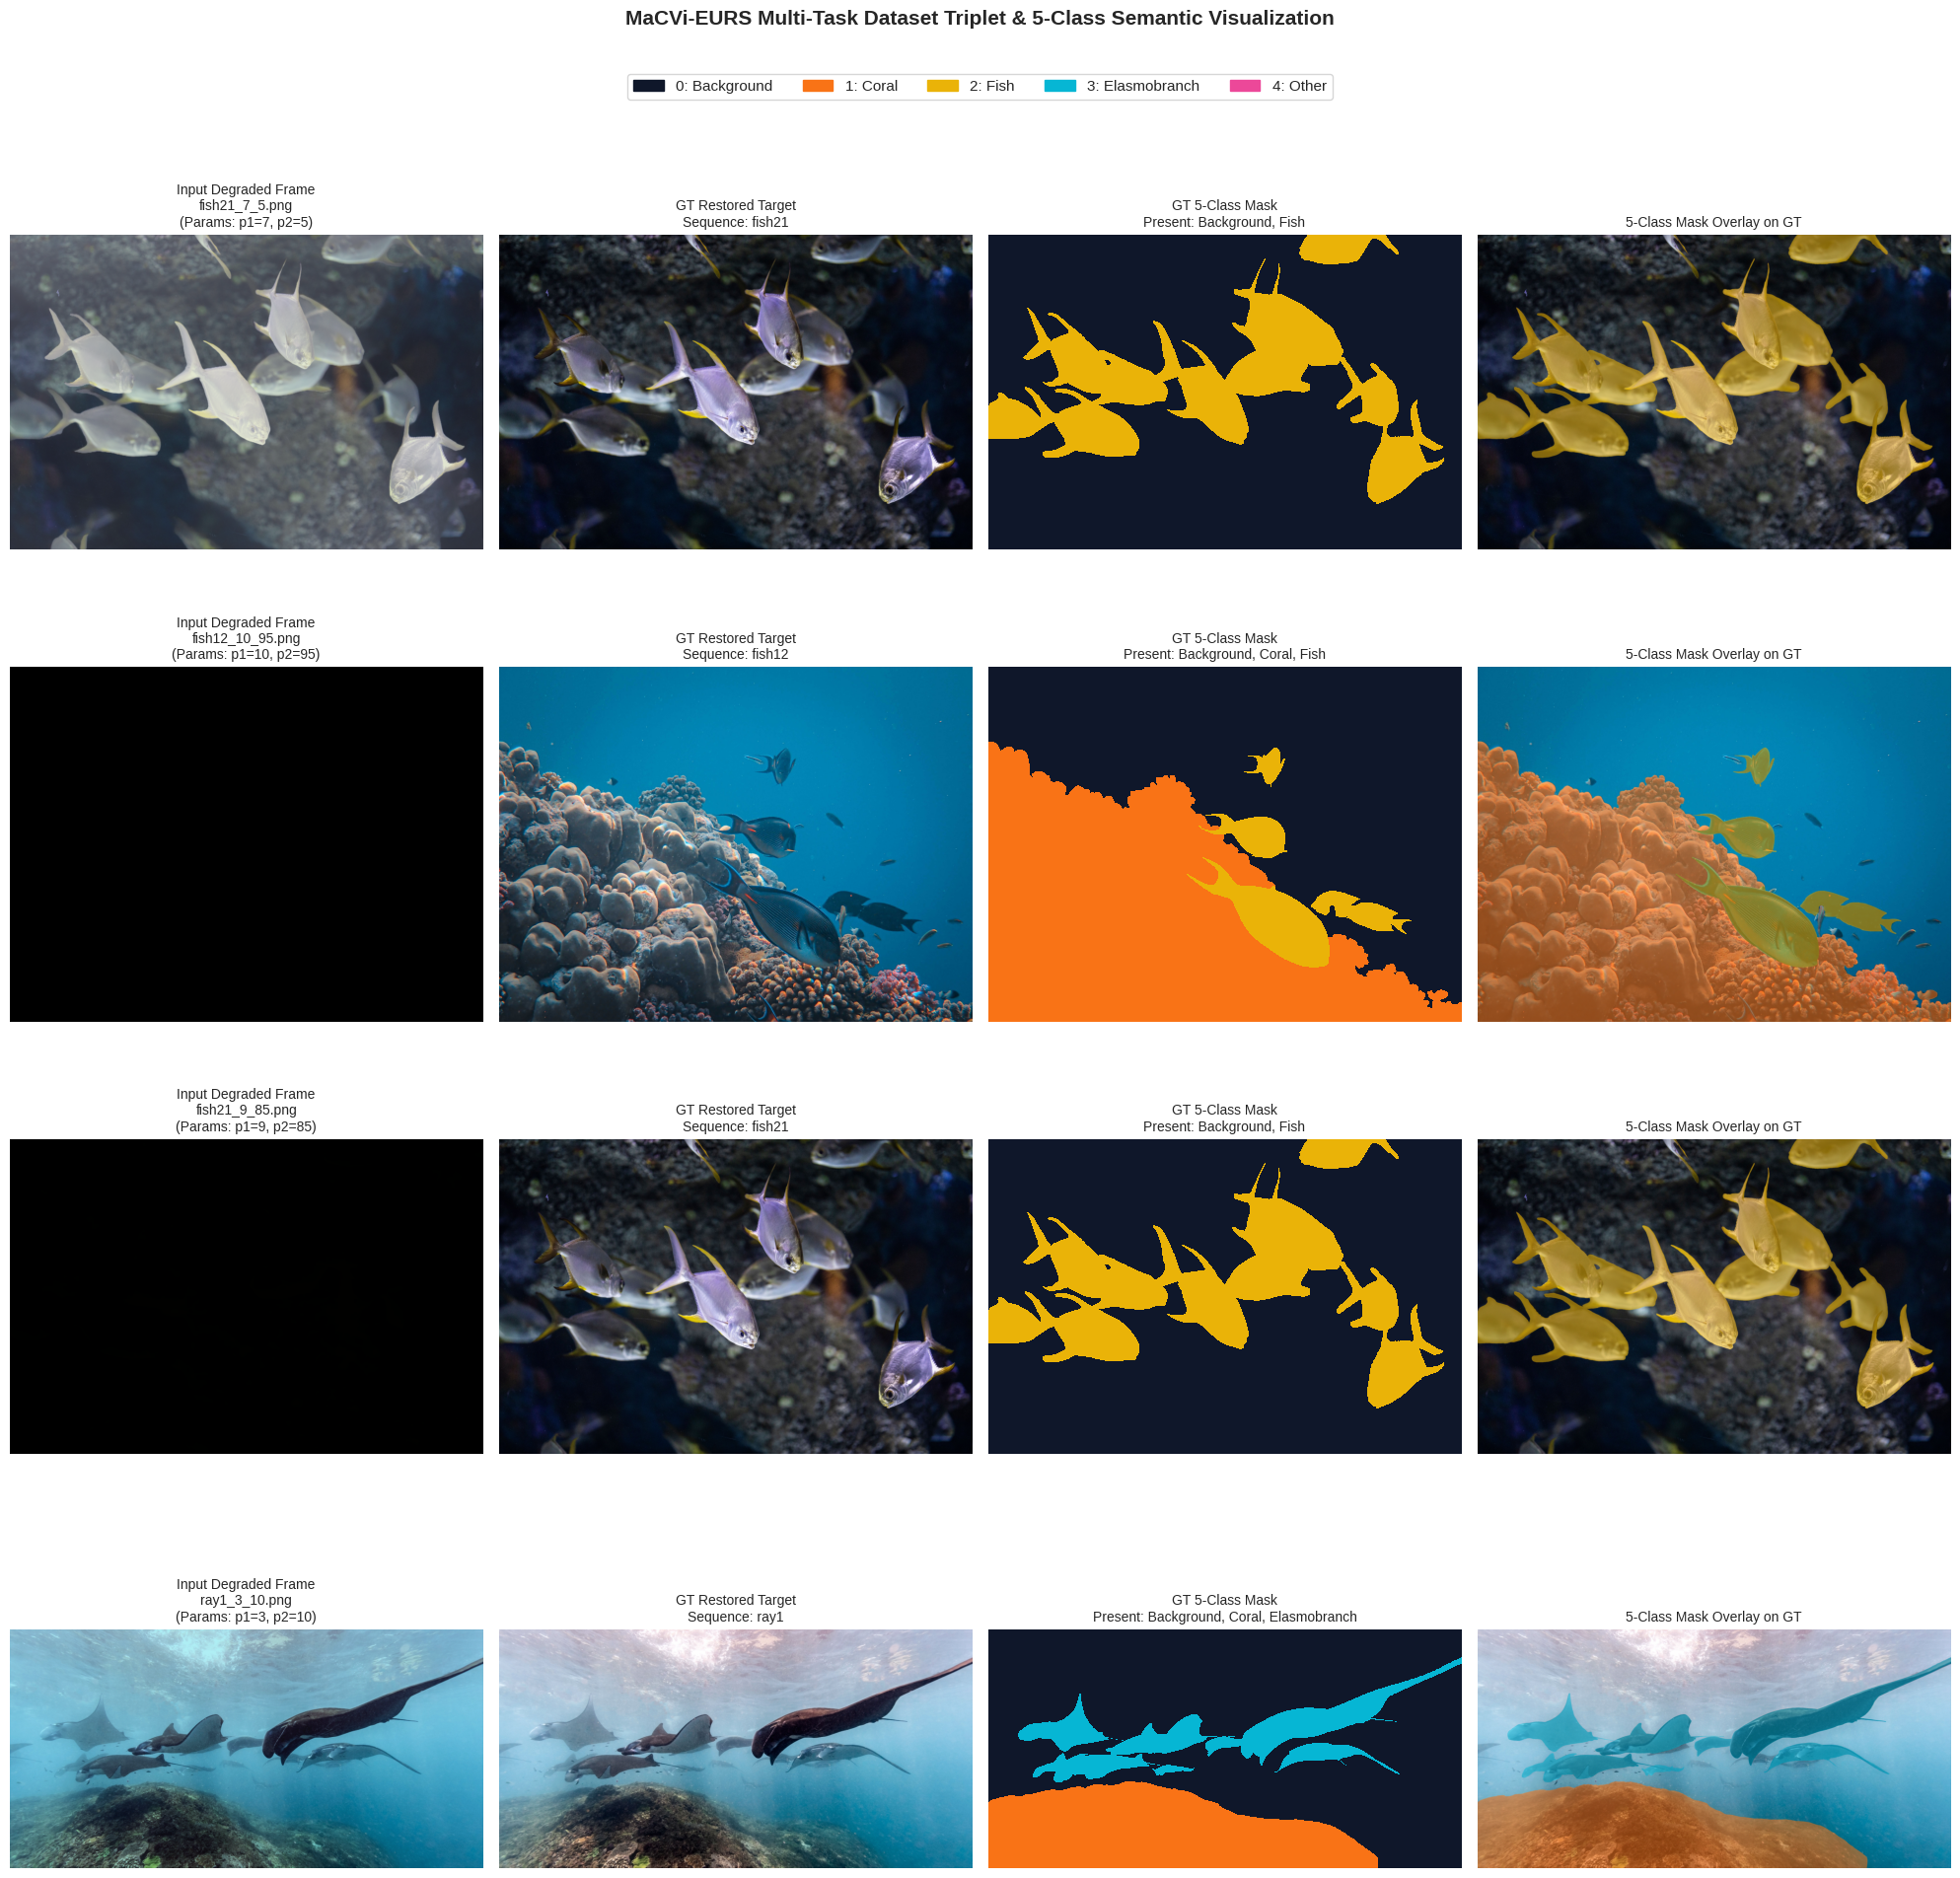

In [5]:
def load_rgb(path):
    if path is None or not os.path.exists(path):
        return None
    img = cv2.imread(str(path))
    if img is None:
        return None
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_mask(path):
    if path is None or not os.path.exists(path):
        return None
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return mask

def colorize_5class_mask(mask):
    """
    Converts single-channel integer mask (0-4) into an RGB colorized array.
    """
    h, w = mask.shape
    colorized = np.zeros((h, w, 3), dtype=np.uint8)
    for class_idx in range(5):
        colorized[mask == class_idx] = CLASS_COLORS_RGB[class_idx]
    return colorized

def plot_5class_triplets(df_samples, num_samples=4):
    valid_rows = df_samples[df_samples["gt_image_path"].notna() & df_samples["gt_mask_path"].notna()]
    if len(valid_rows) == 0:
        print("No paired GT image/mask paths found.")
        return
        
    selected = valid_rows.sample(min(len(valid_rows), num_samples), random_state=42)
    
    fig, axes = plt.subplots(len(selected), 4, figsize=(20, 4.8 * len(selected)))
    if len(selected) == 1:
        axes = np.expand_dims(axes, axis=0)
        
    for i, (_, row) in enumerate(selected.iterrows()):
        deg_img = load_rgb(row["path"])
        gt_img = load_rgb(row["gt_image_path"])
        gt_mask = load_mask(row["gt_mask_path"])
        
        # 1. Degraded Input
        if deg_img is not None:
            axes[i, 0].imshow(deg_img)
        axes[i, 0].set_title(f"Input Degraded Frame\n{row['filename']}\n(Params: p1={row['param1']}, p2={row['param2']})", fontsize=10)
        axes[i, 0].axis("off")
        
        # 2. GT Clean Target
        if gt_img is not None:
            axes[i, 1].imshow(gt_img)
            axes[i, 1].set_title(f"GT Restored Target\nSequence: {row['sequence']}", fontsize=10)
        axes[i, 1].axis("off")
        
        # 3. GT 5-Class Semantic Mask
        if gt_mask is not None:
            im_mask = axes[i, 2].imshow(gt_mask, cmap=CLASS_CMAP, norm=CLASS_NORM, interpolation='nearest')
            unique_cls = np.unique(gt_mask)
            present_classes = [CLASS_NAMES[c] for c in unique_cls if c < 5]
            axes[i, 2].set_title(f"GT 5-Class Mask\nPresent: {', '.join(present_classes)}", fontsize=10)
        axes[i, 2].axis("off")
        
        # 4. Multi-Class Alpha-Blend Overlay
        if gt_img is not None and gt_mask is not None:
            if gt_mask.shape[:2] != gt_img.shape[:2]:
                gt_mask_res = cv2.resize(gt_mask, (gt_img.shape[1], gt_img.shape[0]), interpolation=cv2.INTER_NEAREST)
            else:
                gt_mask_res = gt_mask
                
            color_mask = colorize_5class_mask(gt_mask_res)
            # Blend: Keep background as original, blend foreground classes
            overlay = gt_img.copy()
            fg_bool = gt_mask_res > 0
            overlay[fg_bool] = cv2.addWeighted(gt_img[fg_bool], 0.45, color_mask[fg_bool], 0.55, 0)
            axes[i, 3].imshow(overlay)
            axes[i, 3].set_title("5-Class Mask Overlay on GT", fontsize=10)
        axes[i, 3].axis("off")
        
    # Create unified legend for 5 classes
    patches = [mpatches.Patch(color=CLASS_COLORS_RGB[i]/255.0, label=f"{i}: {CLASS_NAMES[i]}") for i in range(5)]
    fig.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=5, fontsize=11, frameon=True)
    plt.suptitle("MaCVi-EURS Multi-Task Dataset Triplet & 5-Class Semantic Visualization", y=1.05, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

if not df_train.empty:
    plot_5class_triplets(df_train, num_samples=4)

---  
## 6. Degradation Spectrum: Turbidity & Attenuation Progression

### Why this parameter sweep matters:
We fix a single sequence (e.g. `sharkFish` or `fish1`) and display frames across various `param1` and `param2` levels.
- `param1` correlates with **optical water attenuation coefficient** (color cast severity: greenish/blueish tint, red channel extinction).
- `param2` correlates with **turbidity & forward/backward scattering** (contrast loss, veiling light, and edge blur).

Observing this progression allows us to calibrate data augmentations (e.g., synthetic underwater haze modeling during training).

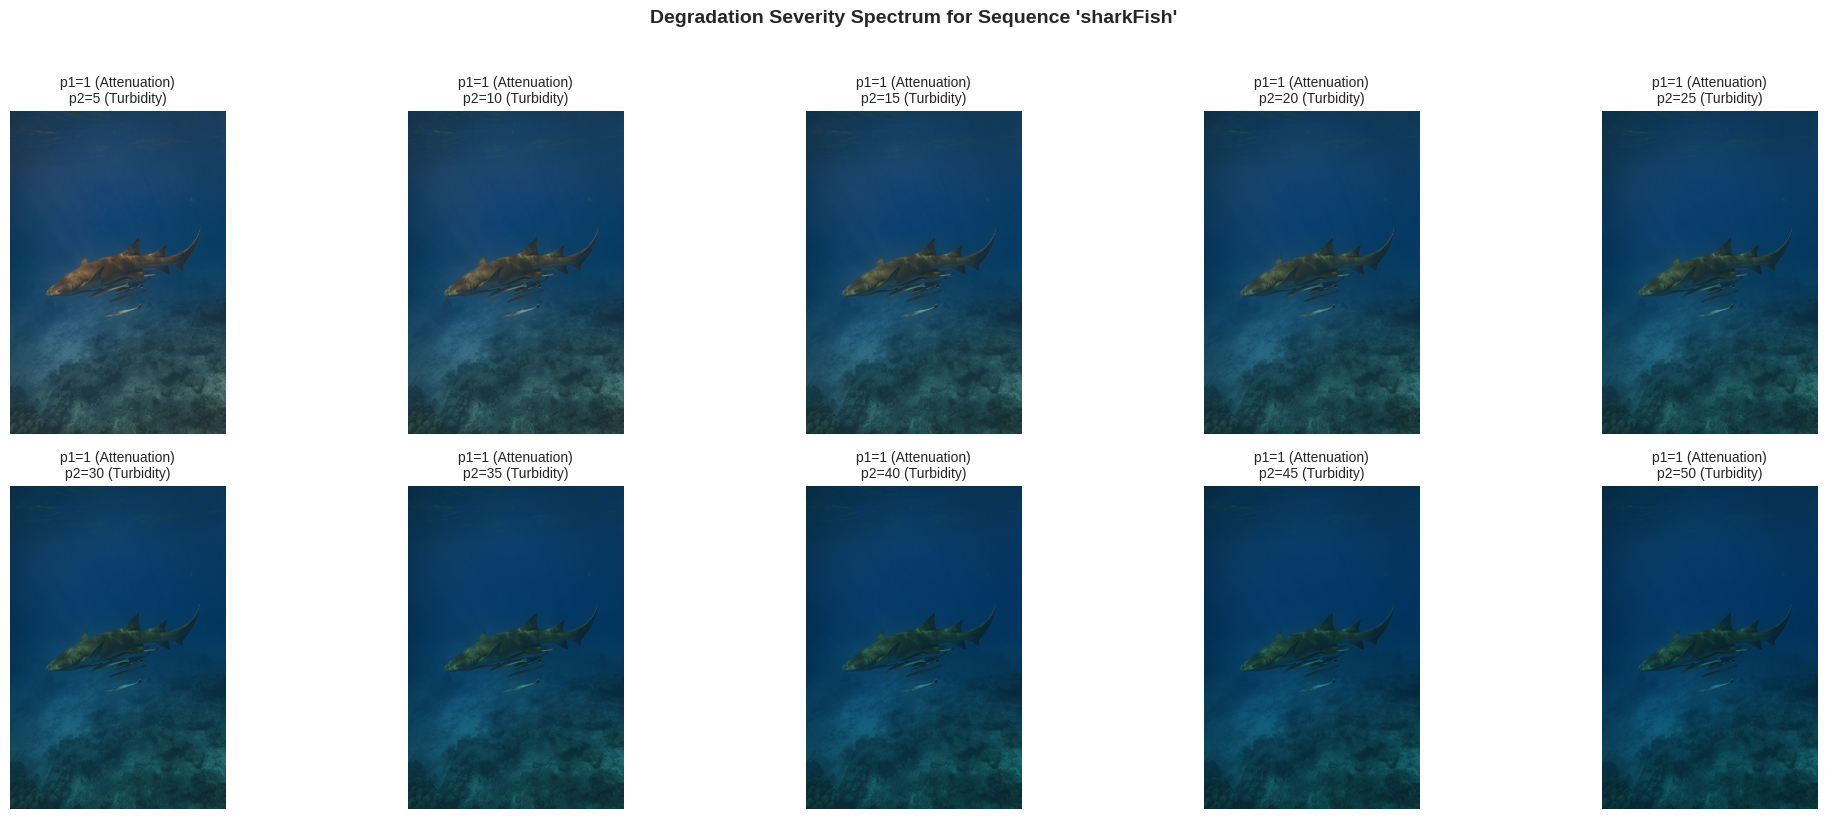

In [6]:
def plot_degradation_grid_for_sequence(df, target_seq=None, max_cols=5):
    if df.empty:
        return
    if target_seq is None:
        target_seq = df["folder_sequence"].value_counts().index[0]
        
    seq_df = df[df["folder_sequence"] == target_seq].copy()
    if seq_df.empty:
        print(f"No samples found for sequence: {target_seq}")
        return
        
    seq_df = seq_df.sort_values(by=["param1", "param2"]).head(10)
    n_images = len(seq_df)
    n_cols = min(max_cols, n_images)
    n_rows = (n_images + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4 * n_rows))
    axes = np.array(axes).reshape(-1)
    
    for idx, (_, row) in enumerate(seq_df.iterrows()):
        img = load_rgb(row["path"])
        if img is not None:
            axes[idx].imshow(img)
        axes[idx].set_title(f"p1={row['param1']} (Attenuation)\np2={row['param2']} (Turbidity)", fontsize=10)
        axes[idx].axis("off")
        
    for j in range(idx + 1, len(axes)):
        axes[j].axis("off")
        
    plt.suptitle(f"Degradation Severity Spectrum for Sequence '{target_seq}'", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

if not df_train.empty:
    plot_degradation_grid_for_sequence(df_train)

---  
## 7. Underwater Color Profile & Channel Attenuation (RGB / LAB / HSV)

### Optical Physics in Underwater Environments:
1. **Wavelength-Dependent Absorption**:
   $$I_c(x) = J_c(x) e^{-\beta_c d(x)} + B_c(1 - e^{-\beta_c d(x)}), \quad c \in \{R, G, B\}$$
   where $\beta_R \gg \beta_G > \beta_B$. Red light drops exponentially with depth, causing the severe low-red peak in the histogram below.
2. **Backscattering Veiling Light ($B_c$)**:
   High baseline in Green and Blue channels creates low dynamic range and compressed contrast.
3. **CIE-LAB Color Space**:
   $L^*$ channel shows compressed luminance dynamic range, while $a^*$ (Green-Red axis) shifts heavily towards negative (green).

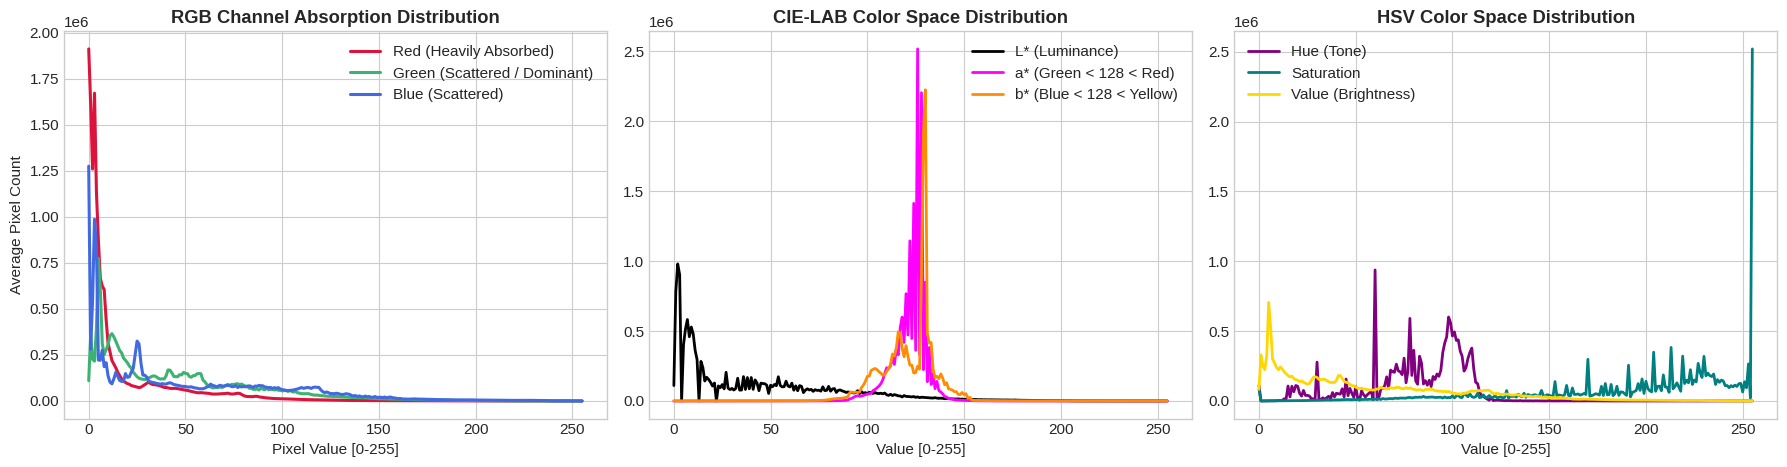

In [7]:
def analyze_color_channels(df_sample, num_samples=40):
    samples = df_sample.sample(min(len(df_sample), num_samples), random_state=42) if len(df_sample) > 0 else df_sample
    
    r_hist, g_hist, b_hist = np.zeros(256), np.zeros(256), np.zeros(256)
    l_hist, a_hist, b_lab_hist = np.zeros(256), np.zeros(256), np.zeros(256)
    h_hist, s_hist, v_hist = np.zeros(256), np.zeros(256), np.zeros(256)
    
    count = 0
    for _, row in samples.iterrows():
        img_bgr = cv2.imread(row["path"])
        if img_bgr is None:
            continue
            
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        
        # RGB
        for c, h in enumerate([r_hist, g_hist, b_hist]):
            hist, _ = np.histogram(img_rgb[:, :, c], bins=256, range=(0, 256))
            h += hist
            
        # LAB
        for c, h in enumerate([l_hist, a_hist, b_lab_hist]):
            hist, _ = np.histogram(img_lab[:, :, c], bins=256, range=(0, 256))
            h += hist
            
        # HSV
        for c, h in enumerate([h_hist, s_hist, v_hist]):
            hist, _ = np.histogram(img_hsv[:, :, c], bins=256, range=(0, 256))
            h += hist
            
        count += 1
        
    if count == 0:
        return
        
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    bins = np.arange(256)
    
    # RGB Histogram
    axes[0].plot(bins, r_hist / count, color='crimson', label='Red (Heavily Absorbed)', lw=2.2)
    axes[0].plot(bins, g_hist / count, color='mediumseagreen', label='Green (Scattered / Dominant)', lw=2.2)
    axes[0].plot(bins, b_hist / count, color='royalblue', label='Blue (Scattered)', lw=2.2)
    axes[0].set_title("RGB Channel Absorption Distribution", fontweight="bold")
    axes[0].set_xlabel("Pixel Value [0-255]")
    axes[0].set_ylabel("Average Pixel Count")
    axes[0].legend()
    
    # LAB Histogram
    axes[1].plot(bins, l_hist / count, color='black', label='L* (Luminance)', lw=2)
    axes[1].plot(bins, a_hist / count, color='magenta', label='a* (Green < 128 < Red)', lw=2)
    axes[1].plot(bins, b_lab_hist / count, color='darkorange', label='b* (Blue < 128 < Yellow)', lw=2)
    axes[1].set_title("CIE-LAB Color Space Distribution", fontweight="bold")
    axes[1].set_xlabel("Value [0-255]")
    axes[1].legend()
    
    # HSV Histogram
    axes[2].plot(bins, h_hist / count, color='purple', label='Hue (Tone)', lw=2)
    axes[2].plot(bins, s_hist / count, color='teal', label='Saturation', lw=2)
    axes[2].plot(bins, v_hist / count, color='gold', label='Value (Brightness)', lw=2)
    axes[2].set_title("HSV Color Space Distribution", fontweight="bold")
    axes[2].set_xlabel("Value [0-255]")
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()

if not df_all.empty:
    analyze_color_channels(df_all, num_samples=50)

---  
## 8. Degradation Quality Benchmarks (PSNR, SSIM & Sharpness Ratio)

### Evaluation Metrics Calculated Here (Mirroring the Official Leaderboard Formula):
1. **PSNR (Peak Signal-to-Noise Ratio)**: Measured in dB; normalized in $[15, 35]\text{ dB}$ window as $\text{PSNR}_{\text{norm}}$.
2. **SSIM (Structural Similarity Index)**: Measures structural pattern retention in $[0, 1]$.
3. **Sharpness Ratio**: Anti-blur metric defined by the Laplacian variance ratio:
   $$\text{sharpness\_ratio} = \frac{\text{Var}\left(\nabla^2 I_{\text{degraded}}\right)}{\text{Var}\left(\nabla^2 I_{\text{clean\_gt}}\right)}$$
   Values $< 1.0$ quantify loss of high-frequency textures caused by water turbidity.

Benchmarking PSNR/SSIM/Sharpness:   0%|          | 0/100 [00:00<?, ?it/s]

,param1,param2,psnr_db,psnr_norm,ssim,sharpness_ratio
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,5.690000,55.700000,12.645300,0.048501,0.426607,0.020702
std,2.627343,28.832676,4.501518,0.110149,0.258306,0.023492
min,1.000000,5.000000,4.470000,0.000000,0.008400,0.000000
25%,4.000000,30.000000,9.102500,0.000000,0.202525,0.002275
50%,6.000000,55.000000,11.725000,0.000000,0.427350,0.011250
75%,8.000000,85.000000,15.420000,0.021025,0.654775,0.032800
max,10.000000,100.000000,27.000000,0.600100,0.912700,0.082200


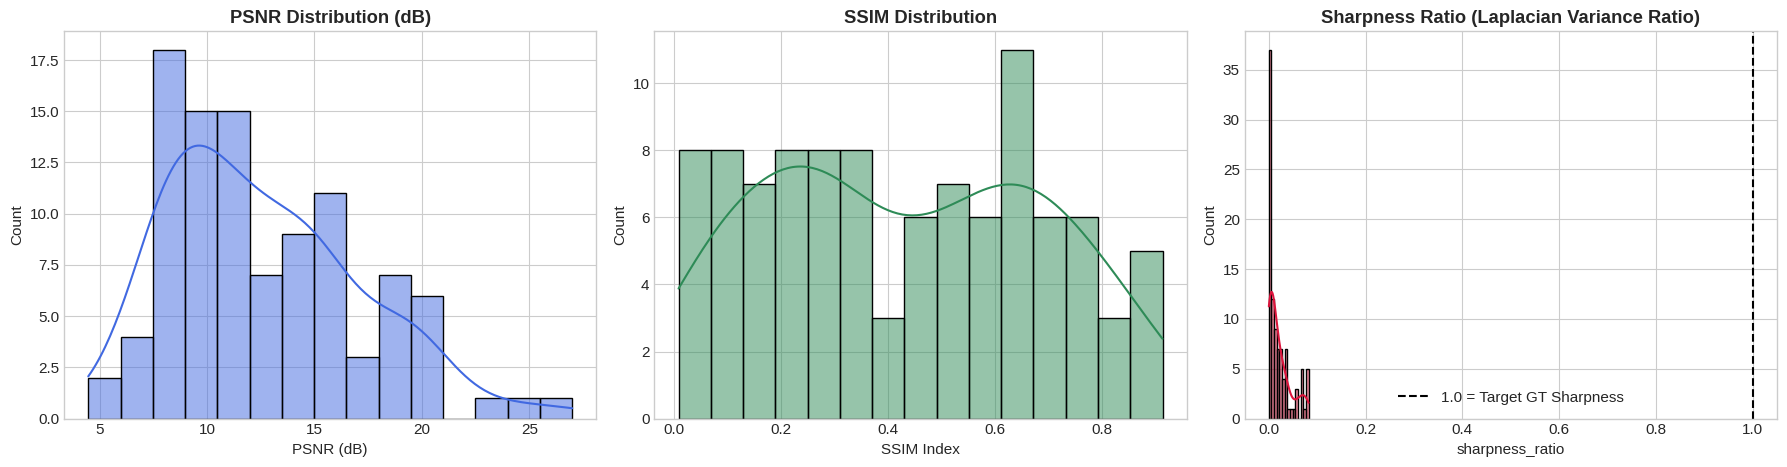

In [8]:
def compute_laplacian_var(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()

def compute_image_metrics(df_train_pairs, max_pairs=80):
    valid_pairs = df_train_pairs[df_train_pairs["gt_image_path"].notna()].copy()
    if len(valid_pairs) == 0:
        print("No GT image pairs found for metric computation.")
        return pd.DataFrame()
        
    samples = valid_pairs.sample(min(len(valid_pairs), max_pairs), random_state=42)
    records = []
    
    for _, row in tqdm(samples.iterrows(), total=len(samples), desc="Benchmarking PSNR/SSIM/Sharpness"):
        deg = cv2.imread(row["path"])
        gt = cv2.imread(row["gt_image_path"])
        
        if deg is None or gt is None:
            continue
            
        if deg.shape != gt.shape:
            gt = cv2.resize(gt, (deg.shape[1], deg.shape[0]))
            
        val_psnr = psnr(gt, deg, data_range=255)
        val_psnr_norm = np.clip((val_psnr - 15.0) / (35.0 - 15.0), 0.0, 1.0)
        val_ssim = ssim(gt, deg, channel_axis=2, data_range=255)
        
        # Sharpness ratio: Degraded Var / GT Var
        deg_var = compute_laplacian_var(deg)
        gt_var = compute_laplacian_var(gt)
        sharp_ratio = (deg_var / (gt_var + 1e-6))
        
        records.append({
            "filename": row["filename"],
            "sequence": row["sequence"],
            "param1": row["param1"],
            "param2": row["param2"],
            "psnr_db": round(val_psnr, 2),
            "psnr_norm": round(val_psnr_norm, 4),
            "ssim": round(val_ssim, 4),
            "sharpness_ratio": round(sharp_ratio, 4)
        })
        
    return pd.DataFrame(records)

df_metrics = compute_image_metrics(df_train, max_pairs=100)
if not df_metrics.empty:
    display(df_metrics.describe())
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    
    # PSNR Distribution
    sns.histplot(df_metrics["psnr_db"], kde=True, ax=axes[0], color="royalblue", bins=15)
    axes[0].set_title("PSNR Distribution (dB)", fontweight="bold")
    axes[0].set_xlabel("PSNR (dB)")
    
    # SSIM Distribution
    sns.histplot(df_metrics["ssim"], kde=True, ax=axes[1], color="seagreen", bins=15)
    axes[1].set_title("SSIM Distribution", fontweight="bold")
    axes[1].set_xlabel("SSIM Index")
    
    # Sharpness Ratio Distribution
    sns.histplot(df_metrics["sharpness_ratio"], kde=True, ax=axes[2], color="crimson", bins=15)
    axes[2].set_title("Sharpness Ratio (Laplacian Variance Ratio)", fontweight="bold")
    axes[2].axvline(1.0, color='black', linestyle='--', label='1.0 = Target GT Sharpness')
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()

---  
## 9. Frequency Domain Profiling (2D Fast Fourier Transform / FFT)

Under-water turbidity acts as a low-pass filter, dissipating fine high-frequency textures (fish scales, coral ridges). We compute the 2D FFT magnitude spectrum to visualize frequency degradation.

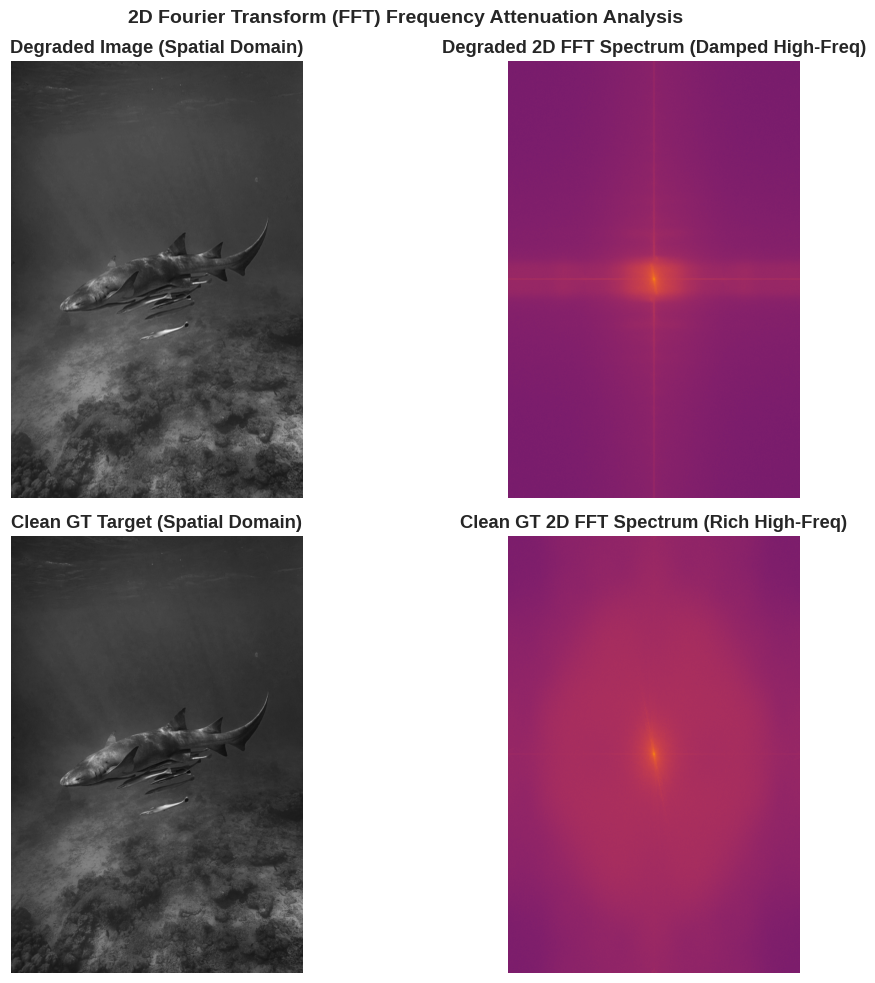

In [9]:
def compute_fft_magnitude(img_gray):
    dft = cv2.dft(np.float32(img_gray), flags=cv2.DFT_COMPLEX_OUTPUT)
    dft_shift = np.fft.fftshift(dft)
    magnitude_spectrum = 20 * np.log(cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1e-6)
    return magnitude_spectrum

if not df_train.empty and df_train["gt_image_path"].notna().any():
    sample_row = df_train[df_train["gt_image_path"].notna()].iloc[0]
    deg_img = cv2.imread(sample_row["path"], cv2.IMREAD_GRAYSCALE)
    gt_img = cv2.imread(sample_row["gt_image_path"], cv2.IMREAD_GRAYSCALE)
    
    if deg_img is not None and gt_img is not None:
        if deg_img.shape != gt_img.shape:
            gt_img = cv2.resize(gt_img, (deg_img.shape[1], deg_img.shape[0]))
            
        deg_fft = compute_fft_magnitude(deg_img)
        gt_fft = compute_fft_magnitude(gt_img)
        
        fig, axes = plt.subplots(2, 2, figsize=(12, 10))
        
        axes[0, 0].imshow(deg_img, cmap='gray')
        axes[0, 0].set_title("Degraded Image (Spatial Domain)", fontweight="bold")
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(deg_fft, cmap='inferno')
        axes[0, 1].set_title("Degraded 2D FFT Spectrum (Damped High-Freq)", fontweight="bold")
        axes[0, 1].axis('off')
        
        axes[1, 0].imshow(gt_img, cmap='gray')
        axes[1, 0].set_title("Clean GT Target (Spatial Domain)", fontweight="bold")
        axes[1, 0].axis('off')
        
        axes[1, 1].imshow(gt_fft, cmap='inferno')
        axes[1, 1].set_title("Clean GT 2D FFT Spectrum (Rich High-Freq)", fontweight="bold")
        axes[1, 1].axis('off')
        
        plt.suptitle("2D Fourier Transform (FFT) Frequency Attenuation Analysis", fontsize=14, fontweight="bold")
        plt.tight_layout()
        plt.show()

---  
## 10. 5-Class Mask Pixel Frequencies, Imbalance & Spatial Heatmaps

### Why per-class analysis is critical for $Q_{\text{seg}}$:
- $Q_{\text{seg}} = \text{F1} \times \text{mIoU} \times \text{coverage\_penalty}$.
- The `coverage_penalty` actively drives $Q_{\text{seg}} \to 0$ if rare classes (e.g. `Elasmobranch` or `Other`) are ignored by the model.
- Below, we compute **exact per-class pixel area percentages** across all masks to quantify class imbalance and build **spatial location heatmaps** for each individual class.

Analyzing 5-Class Masks:   0%|          | 0/100 [00:00<?, ?it/s]

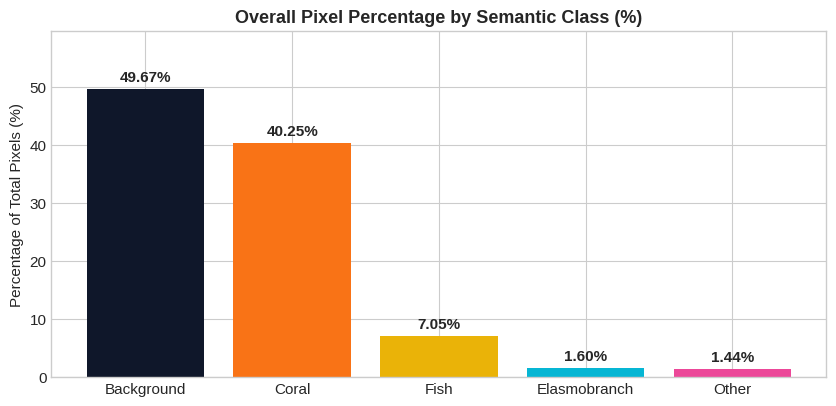

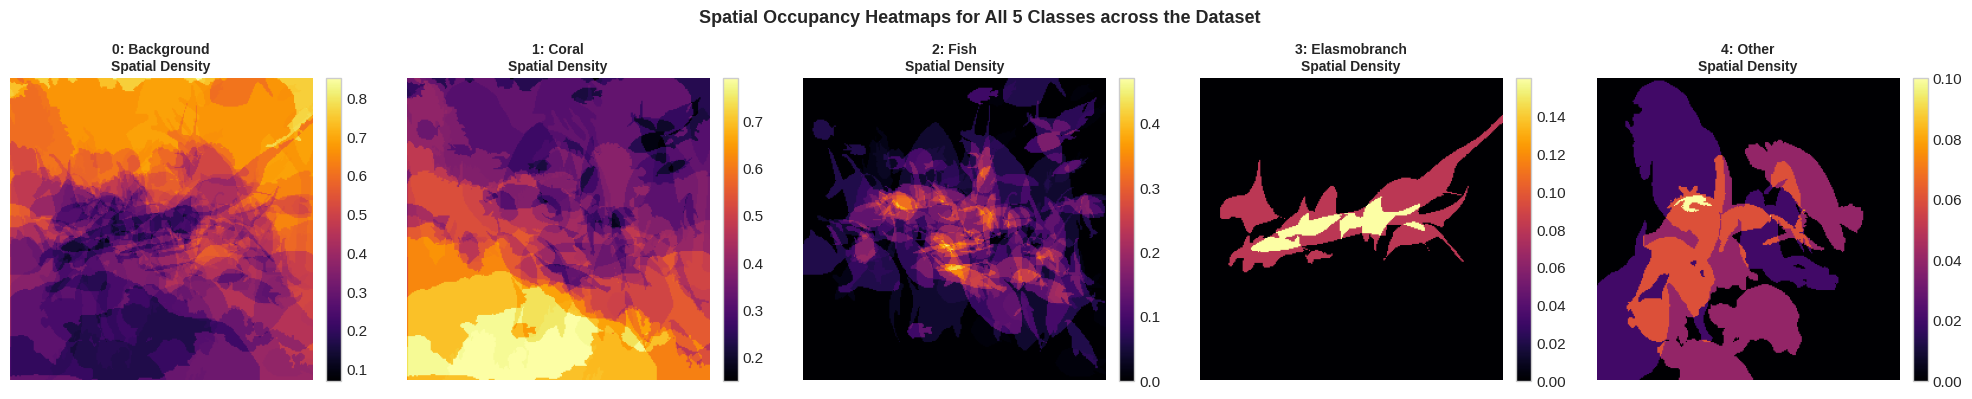

In [10]:
def analyze_5class_masks(df_train_sub, target_shape=(256, 256), max_samples=80):
    valid_masks = df_train_sub[df_train_sub["gt_mask_path"].notna()].copy()
    if len(valid_masks) == 0:
        print("No GT mask paths found for analysis.")
        return
        
    samples = valid_masks.sample(min(len(valid_masks), max_samples), random_state=42)
    
    class_pixel_counts = {i: 0 for i in range(5)}
    total_pixels = 0
    class_heatmaps = {i: np.zeros(target_shape, dtype=np.float32) for i in range(5)}
    count = 0
    
    for _, row in tqdm(samples.iterrows(), total=len(samples), desc="Analyzing 5-Class Masks"):
        mask = load_mask(row["gt_mask_path"])
        if mask is None:
            continue
            
        total_pixels += mask.size
        for c in range(5):
            c_mask = (mask == c).astype(np.float32)
            class_pixel_counts[c] += c_mask.sum()
            resized_c = cv2.resize(c_mask, target_shape, interpolation=cv2.INTER_NEAREST)
            class_heatmaps[c] += resized_c
            
        count += 1
        
    if count == 0:
        return
        
    # 1. Pixel Share Distribution Bar Chart
    pixel_percentages = [100.0 * (class_pixel_counts[c] / total_pixels) for c in range(5)]
    
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bars = ax.bar(CLASS_NAMES, pixel_percentages, color=[CLASS_COLORS_RGB[i]/255.0 for i in range(5)])
    ax.set_title("Overall Pixel Percentage by Semantic Class (%)", fontweight="bold", fontsize=13)
    ax.set_ylabel("Percentage of Total Pixels (%)")
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
    plt.ylim(0, max(pixel_percentages) + 10)
    plt.show()
    
    # 2. Per-Class Spatial Heatmaps
    fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
    for c in range(5):
        density = class_heatmaps[c] / count
        im = axes[c].imshow(density, cmap="inferno", origin="upper")
        axes[c].set_title(f"{c}: {CLASS_NAMES[c]}\nSpatial Density", fontweight="bold", fontsize=10)
        axes[c].axis("off")
        plt.colorbar(im, ax=axes[c], fraction=0.046, pad=0.04)
        
    plt.suptitle("Spatial Occupancy Heatmaps for All 5 Classes across the Dataset", fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

if not df_train.empty:
    analyze_5class_masks(df_train, max_samples=100)

---  
## 11. Unified Modeling Strategy & Track 2 Hardware Compliance

### 🏗️ Recommended Dual-Head Architecture Blueprint

To satisfy **Track 2 on Jetson AGX Orin ($\le 12\text{ GFLOPs}, \le 1.0\text{M params}$)** and achieve high accuracy on **Track 1 ($Q_{\text{seg}} + \text{PSNR} + \text{SSIM}$)**:

```
                               ┌─► Restoration Decoder ──► Output 1: restored_image (1, 3, H, W) in [0, 1]
Input (1, 3, H, W) ──► Shared ─┤
                       Encoder └─► Segmentation Decoder ─► Output 2: seg_logits (1, 5, H, W) [Raw Logits]
```

### 🎯 Key Design Choices

1. **Encoder**: Shared lightweight backbone with simple, hardware-friendly operators (e.g., SimpleGate / NAFBlocks, MobileNetV4-Conv-Small, or SegNeXt-T) keeping parameter count $\approx 500\text{k}$ and FLOPs $\approx 6\text{ GFLOPs}$.
2. **Dual Decoders**:
   - **Restoration Head**: Residual connection from input image with lightweight pixel shuffle or transposed convs, predicting RGB residual $\Delta I \in [0, 1]$.
   - **Segmentation Head**: Lightweight Multi-Scale Feature Aggregation (FPN / MLP) outputting $(1, 5, H, W)$ logits.
3. **Multi-Task Loss Function**:
   $$\mathcal{L}_{\text{total}} = \lambda_{\text{seg}} \mathcal{L}_{\text{seg}} + \lambda_{\text{rest}} \mathcal{L}_{\text{rest}}$$
   - $\mathcal{L}_{\text{seg}} = \mathcal{L}_{\text{CrossEntropy}} + \mathcal{L}_{\text{FocalTversky}}$ (handles severe background vs elasmobranch/coral class imbalance).
   - $\mathcal{L}_{\text{rest}} = \alpha \mathcal{L}_{1} + \beta (1 - \text{SSIM}) + \gamma \mathcal{L}_{\text{Laplacian/Sharpness}}$.
4. **Export & Validation Checklist**:
   - Export ONNX with `save_as_external_data=False` and static input shape $(1, 3, 384, 768)$.
   - Verify local FLOPs and parameter count using `python check_submission_flops.py --onnx your_model.onnx`.
   - For Track 1: Run `python resize_for_submission.py` to ensure exact resolution matching before packaging into `.zip`.